# pyNTAVIS: training an SNN with snnTorch from three-axis AEDAT files

This notebook goes from a folder of labelled three-axis AEDAT recordings to a trained Spiking Neural Network (SNN):

1. Every recording is loaded with `Loaders.loadAEDAT()`.
2. It is cut into fixed-length windows with `Splitters.window_splitter()`. Each window takes the label of its recording.
3. Each window is converted into a `[time steps, addresses]` matrix of spike counts with `Functions.spikes_to_frames()`.
4. The prepared train and validation sets are saved to an output folder (`.npz` files).
5. A spiking network made of leaky integrate-and-fire (LIF) neurons is trained with **snnTorch**.

Times are given in microseconds (µs), the unit of the AEDAT timestamps after `Functions.adapt_timestamps()`.

## 0. Setup (Google Colab only)

If you opened this notebook in **Google Colab**, run this cell first. It downloads the pyNTAVIS repository, installs its modified version of `pyNAVIS` (instead of the PyPI release) and snnTorch, and moves into the `src/examples` folder. PyTorch is already installed in Colab.

To run it locally, install PyTorch and snnTorch in your environment first (`pip install torch snntorch`). In that case this cell only prints where `pyNAVIS` is loaded from.

In [ ]:
# Setup for Google Colab: use the pyNTAVIS version of pyNAVIS from GitHub, not the PyPI one
import os, sys

if 'google.colab' in sys.modules:
    if not os.path.isdir('/content/pyNTAVIS'):
        !git clone --depth 1 https://github.com/juamonsan/pyNTAVIS.git /content/pyNTAVIS
    !pip uninstall -y -q pyNAVIS
    !pip install -q /content/pyNTAVIS/src snntorch
    os.chdir('/content/pyNTAVIS/src/examples')

import pyNAVIS
print('pyNAVIS loaded from:', pyNAVIS.__file__)

## 1. Import the required libraries

In [1]:
%matplotlib inline
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

import snntorch as snn
from snntorch import functional as SF
from snntorch import surrogate

from pyNAVIS import Functions, Loaders, MainSettings, Savers, SpikesFile, Splitters

## 2. Choose the data

### Option A: an experiment of the Fan NTAS dataset

If the folder `FAN_DATASET_PATH` exists, the next cell builds the train and validation folders of one experiment with `fan_dataset.build_experiment()` (see [fan_dataset.py](fan_dataset.py)). The recordings are hard-linked (or copied) into `snn_dataset/experiments/<experiment>_<sensor>_fold<k>/source`, and the prepared data and results are saved next to them, in `.../prepared`.

The metadata of every recording (speed, sensor, load, external noise, internal noise and date) is read from its file name and checked against `Class_Table.csv` in the dataset folder. If you edit `Class_Table.xlsx`, export it again as CSV with the same columns.

The speed field of the file names is `0` (stop), `1` (min), `2` (medium) or `3` (max). In the table, `Fan Speed` can be written as `Stop` (or `0`), `Min`, `Medium` or `Max`. Experiments that say "min and max speed" don't use the medium speed recordings; `1_speed` and `4_state` use every speed present in the dataset.

Each combination of speed, sensor, load and noise was recorded at least 4 times: 3 repetitions on 8 October and a 4th on 14 October. The recordings with internal noise (tape touching the blades) were all made on 14 October and have 5 repetitions. The experiments use **4-fold cross-validation over the repetitions**: fold `k` validates on repetition `k` and trains on the others. The 5th repetition of the internal noise recordings is always used for training. Run the notebook with `FOLD = 1` to `4`, or use the cross-validation loop of section 11, and report the mean ± standard deviation.

**Fold 4 is also a cross-session test**: it trains only on recordings from 8 October and validates only on recordings from 14 October. Compare it with folds 1–3 to see whether the models still work on a different day.


| Experiment | Classes | Recordings |
|---|---|---|
| `0_session_check` | 8 October / 14 October | Min and max speed, no noise. Only the last repetition of 8 October, so both classes have the same size. Leave-one-load-out folds: fold `k` validates on the recordings with `k + 2` magnets |
| `1_speed` | stop / min / medium / max (the speeds present in the dataset) | All loads, no noise |
| `2a_unbalance` | balanced {3, 6} / unbalanced {4, 5} | Min and max speed, no noise |
| `2a_unbalance_min` | balanced / unbalanced | Min speed only, no noise |
| `2a_unbalance_max` | balanced / unbalanced | Max speed only, no noise |
| `2b_unbalance_noise` | balanced / unbalanced | Min and max speed, with and without noise in both sets |
| `2c_unbalance_unseen_noise` | balanced / unbalanced | Train without noise, validate only with noise |
| `2d_unbalance_min_to_max` | balanced / unbalanced | Train at min speed, validate at max speed (no noise) |
| `2d_unbalance_max_to_min` | balanced / unbalanced | Train at max speed, validate at min speed (no noise) |
| `3_load_min`, `3_load_max`, `3_load` | 3 / 4 / 5 / 6 magnets | Min speed, max speed or both (no noise) |
| `4_state` | stop / min-, medium- and max-balanced / min-, medium- and max-unbalanced (the speeds present in the dataset) | All speeds, no noise. `stop` has twice as many recordings as the other classes |
| `5_noise` | tapping / no tapping | All speeds and loads |
| `6a_tape` | tape / no tape | Min and max speed, all loads, no external noise |
| `6b_tape_with_tapping` | tape / no tape | Min and max speed, all loads, with and without external noise in both sets |
| `6c_tape_same_day` | tape / no tape | Min and max speed, no external noise. Leave-one-load-out folds: fold `k` validates on the 14 October recordings with `k + 2` magnets (one repetition with tape, one without) and trains on the other loads from both days |
| `7a_unbalance_with_tape` | balanced / unbalanced | Min and max speed, no external noise, tape in every recording |
| `7b_unbalance_tape_mixed` | balanced / unbalanced | Min and max speed, no external noise, with and without tape in both sets |
| `7c_unbalance_unseen_tape` | balanced / unbalanced | Train without tape, validate only with tape (min and max speed, no external noise) |
| `8_unbalance_and_tape` | balanced / unbalanced × tape / no tape (4 classes) | Min and max speed, no external noise |

Experiments `0`–`5` don't use the recordings with tape. The tape was only recorded at min and max speed, so experiments `6`–`8` don't use the stopped recordings.

**How to read the tape experiments.** All the recordings with tape are from 14 October, but most recordings without tape are from 8 October, so a network could learn to recognise the recording day instead of the tape:

- `0_session_check` measures how much the two days differ without tape. Close to 50 % means the day leaves no trace the network can use.
- In folds 1–3 of `6a`, `6b` and `8`, validation compares recordings without tape from 8 October with recordings with tape from 14 October, so tape and day are mixed and the results are optimistic.
- In **fold 4** of `6a`, `6b` and `8`, validation uses only 14 October, but all the training recordings without tape are from 8 October, so the network can still learn "14 October = tape". A low fold 4 shows that the network takes that shortcut when it can.
- **`6c_tape_same_day` is the fair test**: training has recordings without tape from both days, so the day is no longer a shortcut, and validation compares tape and no tape on the same day, for a load the network has never seen.
- `7a` only uses 14 October, so it is not affected.

`SENSOR` is `'Accel'` or `'Mag'`: the two sensors are never mixed. "No noise" in the table means no external and no internal noise. Notes from a first look at the data:

- The magnetometer barely reacts to the tapping (same event rate with and without noise), so experiments `2b`, `2c` and `5` are only meaningful with the accelerometer.
- With the accelerometer at max speed, unbalanced loads produce clearly more events per second than balanced ones, so that case is easy. **At min speed the accelerometer does not capture the unbalance**: its event rate is barely above the stopped level and shows no vibration at the rotation frequency, and neither the SNN nor simple non-spiking classifiers do better than chance (`2a_unbalance_min` and `3_load_min`).
- The magnetometer does see the unbalance at min speed: unbalanced loads add a clear component at 2× the rotation frequency (about 25 Hz) to its event rate. With the 3 repetitions of 8 October, the SNN reached 100 % in all three folds of `2a_unbalance_min` and `3_load_min`.
- The internal noise (tape) increases the accelerometer's event rate by about 50 % at min speed and 25 % at max speed, but barely changes the magnetometer's.
- When the fan is stopped, the magnetometer's event rate depends a lot on where the magnets stopped, so the stopped recordings can differ widely from one repetition to another.

In Google Colab, the dataset is not part of the repository: upload the `Fan_NTAS_Dataset` folder to `src/examples/snn_dataset/` first.

### Option B: your own dataset

In [2]:
from fan_dataset import EXPERIMENTS, NUM_FOLDS, build_experiment

FAN_DATASET_PATH = 'snn_dataset/Fan_NTAS_Dataset'
EXPERIMENT = '8_unbalance_and_tape'
SENSOR = 'Accel'     # 'Accel' or 'Mag'
FOLD = 1             # repetition used for validation: 1 to NUM_FOLDS (4)

if os.path.isdir(FAN_DATASET_PATH):
    EXPERIMENT_PATH = os.path.join('snn_dataset', 'experiments', '{}_{}_fold{}'.format(EXPERIMENT, SENSOR, FOLD))
    SOURCE_PATH = os.path.join(EXPERIMENT_PATH, 'source')
    OUTPUT_PATH = os.path.join(EXPERIMENT_PATH, 'prepared')
    build_experiment(FAN_DATASET_PATH, SOURCE_PATH, EXPERIMENT, SENSOR, FOLD)
else:
    # Option B: your own dataset (or the demo dataset of section 4)
    SOURCE_PATH = 'snn_dataset/source'
    OUTPUT_PATH = 'snn_dataset/prepared'
print('SOURCE_PATH:', SOURCE_PATH, '| OUTPUT_PATH:', OUTPUT_PATH)

[fan_dataset] > 352 recordings, 80 combinations
[fan_dataset] > 8_unbalance_and_tape (Accel, fold 1): Balanced / unbalanced and tape / no tape (4 classes). Min and max speed, no external noise.
  train      balanced_no_tape: 12, balanced_tape: 16, unbalanced_no_tape: 12, unbalanced_tape: 16  (dates: 20261008, 20261014)
  validation balanced_no_tape: 4, balanced_tape: 4, unbalanced_no_tape: 4, unbalanced_tape: 4  (dates: 20261008, 20261014)
SOURCE_PATH: snn_dataset/experiments/8_unbalance_and_tape_Accel_fold1/source | OUTPUT_PATH: snn_dataset/experiments/8_unbalance_and_tape_Accel_fold1/prepared


If you don't use the Fan NTAS dataset, put your recordings in `SOURCE_PATH` with this structure:

`SOURCE_PATH` must contain a `train` and a `validation` folder. Inside each of them there is **one subfolder per class**, named after the class, with the AEDAT recordings of that class:

```
SOURCE_PATH/
├── train/
│   ├── class_a/
│   │   ├── recording_01.aedat
│   │   └── recording_02.aedat
│   └── class_b/
│       └── ...
└── validation/
    ├── class_a/
    └── class_b/
```

Class names are taken from the `train` folder (sorted alphabetically). Keep **whole recordings** in either `train` or `validation`, never windows of the same recording in both: overlapping windows of one recording are almost identical, and mixing them would give an over-optimistic validation accuracy.

## 3. Window and frame parameters

| Parameter | Meaning |
|---|---|
| `settings` | `MainSettings` of the recordings (the same values as in the three-axis tutorial) |
| `WINDOW_SIZE` | Length of each window, in µs |
| `TRAIN_STRIDE` | Time between consecutive training windows. Smaller than `WINDOW_SIZE` means overlapping windows (more training samples) |
| `VALIDATION_STRIDE` | Same for validation. Equal to `WINDOW_SIZE` so validation windows don't overlap |
| `TIME_STEP` | Width of each SNN time step, in µs. Each window has `WINDOW_SIZE / TIME_STEP` time steps |
| `MIN_SPIKES` | Windows with fewer spikes are discarded (silent parts of a recording) |
| `BINARY_FRAMES` | `True`: each input says only whether an address fired in a time step. `False`: number of spikes |

A window should contain several revolutions of the fan. In the Fan NTAS recordings the event rate oscillates at about 12.5 Hz at min speed and 31 Hz at max speed, probably the rotation frequency (80 ms and 32 ms per revolution). The default window of 200 ms covers about 2.5 revolutions at min speed. Try 100, 200 and 400 ms to see the trade-off between detection time and accuracy.

In [3]:
settings = MainSettings(num_channels=43, mono_stereo=MainSettings.THREE_AXIS, on_off_both=1,
                        address_size=4, ts_tick=1, bin_size=20000, verbose=False)

WINDOW_SIZE = 200_000        # 200 ms
TRAIN_STRIDE = 100_000       # 50 % overlap
VALIDATION_STRIDE = WINDOW_SIZE
TIME_STEP = 1_000            # 1 ms -> 200 time steps per window
MIN_SPIKES = 50
BINARY_FRAMES = False

NUM_ADDRESSES = settings.addresses_per_source * settings.num_sources
NUM_STEPS = int(np.ceil(WINDOW_SIZE / TIME_STEP))
print('Inputs per time step:', NUM_ADDRESSES, '| time steps per window:', NUM_STEPS)

Inputs per time step: 258 | time steps per window: 200


## 4. (Optional) Create a demo dataset

**Only used when there is no data in `SOURCE_PATH`** (neither the Fan NTAS dataset nor your own). The cell does nothing when `SOURCE_PATH` exists.

To check that the whole pipeline works, it builds a tiny dataset from the example file `NTAS_Accel_3Axxis_43ch_ONOFF_addr4b_ts1.aedat`:

- class `xyz`: the original recording;
- class `yzx`: the same recording with the axes rotated (X data moved to the Y addresses, Y to Z and Z to X).

The first second of the recording goes to `train` (two files of 0.5 s per class) and the rest to `validation`. **These labels are artificial**: the demo only shows that the code runs, not how well an SNN classifies real signals.

In [4]:
def save_segment(spikes_file, start, end, path, axis_shift=0):
    """Saves the spikes in [start, end) as an AEDAT file, optionally rotating the axes by axis_shift positions."""
    addresses = np.asarray(spikes_file.addresses)
    timestamps = np.asarray(spikes_file.timestamps)
    mask = (timestamps >= start) & (timestamps < end)
    block = settings.addresses_per_source
    shifted = (addresses[mask] + axis_shift * block) % (block * settings.num_sources)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    Savers.save_AEDAT(SpikesFile(shifted, timestamps[mask] - start), path, settings)


if not os.path.isdir(SOURCE_PATH):
    demo_file = Loaders.loadAEDAT('test_files/NTAS_Accel_3Axxis_43ch_ONOFF_addr4b_ts1.aedat', settings)
    Functions.adapt_timestamps(demo_file, settings)
    end = demo_file.max_ts + 1
    segments = {'train': [(0, 500_000), (500_000, 1_000_000)], 'validation': [(1_000_000, end)]}

    for class_name, axis_shift in [('xyz', 0), ('yzx', 1)]:
        for split, ranges in segments.items():
            for i, (start, stop) in enumerate(ranges):
                save_segment(demo_file, start, stop,
                             os.path.join(SOURCE_PATH, split, class_name, 'demo_' + str(i)), axis_shift)
    print('Demo dataset created in', SOURCE_PATH)
else:
    print('Using the existing dataset in', SOURCE_PATH)

Using the existing dataset in snn_dataset/experiments/8_unbalance_and_tape_Accel_fold1/source


## 5. Prepare the train and validation sets

For every recording, `prepare_split()`:

1. loads it with `Loaders.loadAEDAT()` and makes its timestamps start at 0 µs;
2. cuts it into windows with `Splitters.window_splitter()`. Timestamps inside each window are relative to the window start;
3. converts every window into a `[NUM_STEPS, NUM_ADDRESSES]` matrix with `Functions.spikes_to_frames()`.

Each split is saved in `OUTPUT_PATH` as a compressed `.npz` file with:

- `frames`: windows, shape `[num_windows, NUM_STEPS, NUM_ADDRESSES]`;
- `labels`: class index of each window;
- `recordings`: index of the recording each window comes from, and `recording_names`: the path of each recording. Both are used for the per-recording evaluation at the end.

The parameters used are saved in `config.json` next to them.

In [5]:
def prepare_dataset(source_path, output_path, verbose=True):
    """Windows every recording of source_path/train and source_path/validation and saves train.npz, validation.npz and config.json in output_path."""
    class_names = sorted(d for d in os.listdir(os.path.join(source_path, 'train'))
                         if os.path.isdir(os.path.join(source_path, 'train', d)))
    if verbose:
        print('Classes:', class_names)

    def prepare_split(split, stride):
        split_path = os.path.join(source_path, split)
        unknown = set(os.listdir(split_path)) - set(class_names)
        if unknown:
            print('Warning: classes not present in train are ignored:', sorted(unknown))

        frames, labels, recordings, recording_names = [], [], [], []
        for label, class_name in enumerate(class_names):
            files = sorted(glob.glob(os.path.join(split_path, class_name, '*.aedat')))
            num_windows = 0
            for path in files:
                spikes_file = Loaders.loadAEDAT(path, settings)
                Functions.adapt_timestamps(spikes_file, settings)
                windows = Splitters.window_splitter(spikes_file, settings, WINDOW_SIZE, stride=stride, min_spikes=MIN_SPIKES)

                for window in windows:
                    frames.append(Functions.spikes_to_frames(window, settings, TIME_STEP, duration=WINDOW_SIZE,
                                                             start_ts=0, binary=BINARY_FRAMES))
                    labels.append(label)
                    recordings.append(len(recording_names))
                recording_names.append(os.path.relpath(path, source_path))
                num_windows += len(windows)
            if verbose:
                print('  {:<10} {:<20} {:>4} recordings -> {:>6} windows'.format(split, class_name, len(files), num_windows))

        data = dict(frames=np.stack(frames), labels=np.array(labels), recordings=np.array(recordings),
                    recording_names=np.array(recording_names), class_names=np.array(class_names))
        np.savez_compressed(os.path.join(output_path, split + '.npz'), **data)
        return data

    os.makedirs(output_path, exist_ok=True)
    train_data = prepare_split('train', TRAIN_STRIDE)
    validation_data = prepare_split('validation', VALIDATION_STRIDE)

    config = dict(num_channels=settings.num_channels, mono_stereo=settings.mono_stereo, on_off_both=settings.on_off_both,
                  address_size=settings.address_size, ts_tick=settings.ts_tick, window_size_us=WINDOW_SIZE,
                  train_stride_us=TRAIN_STRIDE, validation_stride_us=VALIDATION_STRIDE, time_step_us=TIME_STEP,
                  min_spikes=MIN_SPIKES, binary_frames=BINARY_FRAMES, class_names=class_names, source_path=source_path)
    with open(os.path.join(output_path, 'config.json'), 'w') as f:
        json.dump(config, f, indent=2)

    if verbose:
        print('Train frames:', train_data['frames'].shape, '| validation frames:', validation_data['frames'].shape)
    return train_data, validation_data


train_data, validation_data = prepare_dataset(SOURCE_PATH, OUTPUT_PATH)
CLASS_NAMES = list(train_data['class_names'])

Classes: ['balanced_no_tape', 'balanced_tape', 'unbalanced_no_tape', 'unbalanced_tape']
  train      balanced_no_tape       12 recordings ->    640 windows
  train      balanced_tape          16 recordings ->    861 windows
  train      unbalanced_no_tape     12 recordings ->    645 windows
  train      unbalanced_tape        16 recordings ->    851 windows
  validation balanced_no_tape        4 recordings ->    108 windows
  validation balanced_tape           4 recordings ->    108 windows
  validation unbalanced_no_tape      4 recordings ->    108 windows
  validation unbalanced_tape         4 recordings ->    108 windows
Train frames: (2997, 200, 258) | validation frames: (432, 200, 258)


### Look at one prepared window

Each window is the input the SNN receives: one row per time step and one column per address. The vertical lines separate the X, Y and Z address blocks.

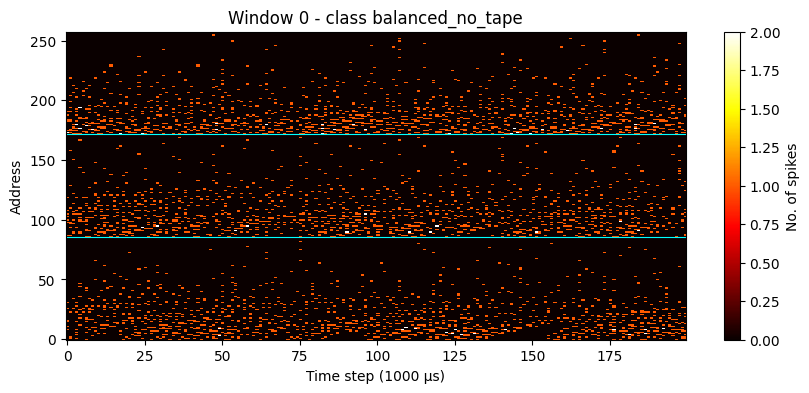

In [6]:
example = train_data['frames'][0]
plt.figure(figsize=(10, 4))
plt.imshow(example.T, aspect='auto', origin='lower', cmap='hot', interpolation='nearest')
for axis in range(1, settings.num_sources):
    plt.axhline(axis * settings.addresses_per_source - 0.5, color='cyan', linewidth=0.8)
plt.xlabel('Time step (' + str(TIME_STEP) + ' µs)')
plt.ylabel('Address')
plt.title('Window 0 - class ' + CLASS_NAMES[train_data['labels'][0]])
plt.colorbar(label='No. of spikes')
plt.show()

## 6. Load the prepared data

The `.npz` files are loaded from `OUTPUT_PATH`, so once the data is prepared you can start the notebook from here. The windows are wrapped in PyTorch `DataLoader`s that return batches of shape `[batch, NUM_STEPS, NUM_ADDRESSES]`.

In [7]:
BATCH_SIZE = 16

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def make_loaders(output_path):
    """Loads train.npz and validation.npz from output_path and wraps them in DataLoaders."""
    loaded = {}
    for split in ['train', 'validation']:
        data = np.load(os.path.join(output_path, split + '.npz'))
        dataset = TensorDataset(torch.tensor(data['frames'], dtype=torch.float32),
                                torch.tensor(data['labels'], dtype=torch.long))
        loaded[split] = (data, DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=(split == 'train')))
    return loaded['train'][0], loaded['validation'][0], loaded['train'][1], loaded['validation'][1]


train_npz, validation_npz, train_loader, validation_loader = make_loaders(OUTPUT_PATH)
CLASS_NAMES = list(train_npz['class_names'])
print('Train windows:', len(train_loader.dataset), '| validation windows:', len(validation_loader.dataset), '| device:', device)

Train windows: 2997 | validation windows: 432 | device: cpu


## 7. Define the SNN

A simple feed-forward network of leaky integrate-and-fire neurons (`snn.Leaky`):

`NUM_ADDRESSES` inputs → fully connected → `NUM_HIDDEN` LIF neurons → fully connected → one LIF output neuron per class

The network is simulated for `NUM_STEPS` time steps. At every step it receives one row of the window. The predicted class is the output neuron that fires the most spikes. During training, the output neuron of the correct class is asked to fire in `CORRECT_RATE` (80 %) of the time steps and the other output neurons in `INCORRECT_RATE` (20 %) (see section 8). The membrane potential carries information between time steps, so the network can use the temporal structure of the signal. Spikes are not differentiable, so training uses a *surrogate gradient* (`fast_sigmoid`).

For harder tasks, try a recurrent layer (`snn.RLeaky`), more hidden neurons or a learnable decay rate (`learn_beta=True`).

In [8]:
NUM_HIDDEN = 128
BETA = 0.9          # membrane decay rate per time step
CORRECT_RATE = 0.8      # target firing rate of the output neuron of the correct class (fraction of time steps)
INCORRECT_RATE = 0.2    # target firing rate of the other output neurons

class SpikingNet(nn.Module):
    def __init__(self, num_inputs, num_hidden, num_outputs, beta):
        super().__init__()
        spike_grad = surrogate.fast_sigmoid(slope=25)
        self.fc1 = nn.Linear(num_inputs, num_hidden)
        self.lif1 = snn.Leaky(beta=beta, spike_grad=spike_grad)
        self.fc2 = nn.Linear(num_hidden, num_outputs)
        self.lif2 = snn.Leaky(beta=beta, spike_grad=spike_grad)

    def forward(self, x):
        # x: [batch, time steps, inputs] -> output spikes: [time steps, batch, outputs]
        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()
        spk_out = []
        for step in range(x.shape[1]):
            spk1, mem1 = self.lif1(self.fc1(x[:, step]), mem1)
            spk2, mem2 = self.lif2(self.fc2(spk1), mem2)
            spk_out.append(spk2)
        return torch.stack(spk_out)


net = SpikingNet(NUM_ADDRESSES, NUM_HIDDEN, len(CLASS_NAMES), BETA).to(device)
print(net)

SpikingNet(
  (fc1): Linear(in_features=258, out_features=128, bias=True)
  (lif1): Leaky()
  (fc2): Linear(in_features=128, out_features=4, bias=True)
  (lif2): Leaky()
)


### Architecture of the network

The figure is drawn from the `net` object, so it follows `NUM_HIDDEN`, `BETA`, `CORRECT_RATE`, `INCORRECT_RATE` and the number of classes of the selected experiment. Only a few neurons of each layer are drawn: every drawn input neuron stands for a group of addresses of one axis, and every line stands for the full connection between two layers (each connection has its own trained weight).

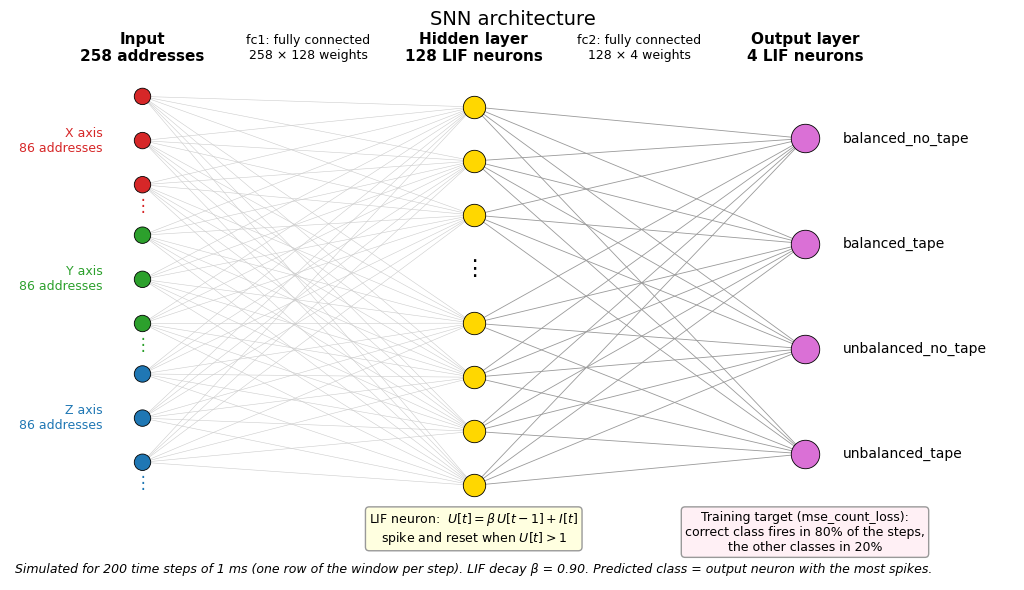

In [9]:
def plot_snn_architecture(net, class_names, max_drawn=7):
    """Draws the layers of a SpikingNet: input addresses (X, Y, Z blocks), hidden LIF layer and output LIF layer."""
    num_inputs, num_hidden, num_outputs = net.fc1.in_features, net.fc1.out_features, net.fc2.out_features
    beta = float(net.lif1.beta)
    block = settings.addresses_per_source
    axis_colors = ['tab:red', 'tab:green', 'tab:blue']

    fig, ax = plt.subplots(figsize=(11, 6))
    ax.set_xlim(-0.6, 3.95)
    ax.set_ylim(-1.35, 1.25)
    ax.axis('off')

    def column(x, n, drawn, top=0.9, bottom=-0.9):
        """Vertical positions of the drawn neurons of a layer, with a gap for the ones that are not drawn."""
        if n <= drawn:
            return list(np.linspace(top, bottom, n) if n > 1 else [0.0]), None
        ys = list(np.linspace(top, bottom, drawn + 1))
        gap = ys.pop(drawn // 2)
        return ys, gap

    # Input layer: a few addresses of each axis block
    input_ys, input_colors = [], []
    per_axis = 3
    for axis, (label, color) in enumerate(zip(settings.source_labels, axis_colors)):
        top = 0.95 - axis * 0.66
        ys = np.linspace(top, top - 0.42, per_axis)
        input_ys += list(ys)
        input_colors += [color] * per_axis
        ax.text(-0.18, ys.mean(), '{}\n{} addresses'.format(label, block), ha='right', va='center', fontsize=9, color=color)
        ax.text(0, ys[-1] - 0.1, '⋮', ha='center', va='center', fontsize=12, color=color)

    hidden_ys, hidden_gap = column(1.5, num_hidden, max_drawn)
    output_ys, _ = column(3.0, num_outputs, max_drawn, top=0.25 * (num_outputs - 1), bottom=-0.25 * (num_outputs - 1))

    # Connections (fully connected layers)
    for y0 in input_ys:
        for y1 in hidden_ys:
            ax.plot([0, 1.5], [y0, y1], color='0.8', linewidth=0.4, zorder=1)
    for y0 in hidden_ys:
        for y1 in output_ys:
            ax.plot([1.5, 3.0], [y0, y1], color='0.6', linewidth=0.6, zorder=1)

    # Neurons
    ax.scatter([0] * len(input_ys), input_ys, s=140, c=input_colors, edgecolors='black', linewidths=0.6, zorder=3)
    ax.scatter([1.5] * len(hidden_ys), hidden_ys, s=260, c='gold', edgecolors='black', linewidths=0.6, zorder=3)
    if hidden_gap is not None:
        ax.text(1.5, hidden_gap, '⋮', ha='center', va='center', fontsize=16)
    ax.scatter([3.0] * len(output_ys), output_ys, s=420, c='orchid', edgecolors='black', linewidths=0.6, zorder=3)
    for y, name in zip(output_ys, class_names):
        ax.text(3.17, y, name, ha='left', va='center', fontsize=10)
    ax.text(3.0, -1.02, 'Training target (mse_count_loss):\ncorrect class fires in {:.0%} of the steps,\nthe other classes in {:.0%}'.format(
                CORRECT_RATE, INCORRECT_RATE),
            ha='center', va='top', fontsize=9, bbox=dict(boxstyle='round', facecolor='lavenderblush', edgecolor='0.6'))

    # Layer titles and connection labels
    ax.text(0, 1.18, 'Input\n{} addresses'.format(num_inputs), ha='center', va='center', fontsize=11, fontweight='bold')
    ax.text(1.5, 1.18, 'Hidden layer\n{} LIF neurons'.format(num_hidden), ha='center', va='center', fontsize=11, fontweight='bold')
    ax.text(3.0, 1.18, 'Output layer\n{} LIF neurons'.format(num_outputs), ha='center', va='center', fontsize=11, fontweight='bold')
    ax.text(0.75, 1.18, 'fc1: fully connected\n{} × {} weights'.format(num_inputs, num_hidden), ha='center', va='center', fontsize=9)
    ax.text(2.25, 1.18, 'fc2: fully connected\n{} × {} weights'.format(num_hidden, num_outputs), ha='center', va='center', fontsize=9)
    ax.text(1.5, -1.02, 'LIF neuron:  $U[t] = \\beta\\, U[t-1] + I[t]$\nspike and reset when $U[t] > 1$', ha='center', va='top',
            fontsize=9, bbox=dict(boxstyle='round', facecolor='lightyellow', edgecolor='0.6'))

    ax.text(1.5, -1.3, 'Simulated for {} time steps of {:g} ms (one row of the window per step). LIF decay β = {:.2f}. '
            'Predicted class = output neuron with the most spikes.'.format(NUM_STEPS, TIME_STEP / 1000, beta),
            ha='center', va='center', fontsize=9, style='italic')
    ax.set_title('SNN architecture', fontsize=14)
    plt.tight_layout()
    plt.show()


plot_snn_architecture(net, CLASS_NAMES)

## 8. Train

The loss is `SF.mse_count_loss()`: the mean squared error between the number of spikes of each output neuron and its target, which is `CORRECT_RATE` × `NUM_STEPS` spikes for the output neuron of the correct class and `INCORRECT_RATE` × `NUM_STEPS` for the others. The targets are not 100 % and 0 %, so every output neuron is asked to fire. This keeps a learning signal even at the start of training, when the output neurons don't spike yet. With the earlier loss (`SF.ce_rate_loss()`), silent output neurons left the network stuck in some folds. After every epoch the model is evaluated on the validation windows, and the model with the lowest validation loss so far is saved to `OUTPUT_PATH/snn_model.pt`. The loss is a better selection criterion than the accuracy, which often reaches its maximum early and then stops changing.

`NUM_EPOCHS`, `LEARNING_RATE` and `BATCH_SIZE` (section 6) are starting values. What matters is the total number of weight updates (`NUM_EPOCHS × train windows / BATCH_SIZE`): with very few windows, use a small batch or more epochs. With a large dataset, increase `BATCH_SIZE` to train faster.

**Automatic restart.** If training never starts, the training accuracy stays at the chance level: the fraction of training windows of the most frequent class (0.5 for 2 balanced classes, 0.25 for 4). If the training accuracy hasn't risen at least `RESTART_MARGIN` (5 percentage points) above that level after `RESTART_PATIENCE` epochs, training restarts once with another random seed (`RANDOM_SEED + 1`). If the second attempt is also stuck, training stops with a `TrainingFailedError` asking you to review the data. In the cross-validation loop (section 11), that fold is reported as failed and left out of the averages, and the other folds continue.

A restart is only triggered when the network learns nothing at all, not even the training windows. If the training accuracy rises but the validation accuracy stays low, training continues normally: that usually means the classes can't be told apart in the validation recordings, which a new seed won't fix.

In [10]:
NUM_EPOCHS = 20
LEARNING_RATE = 2e-3
RANDOM_SEED = 0          # seed of the first attempt; a restart uses RANDOM_SEED + 1
RESTART_PATIENCE = 5     # epochs to wait before deciding that training is stuck
RESTART_MARGIN = 0.05    # training accuracy must rise this much above the chance level
MAX_ATTEMPTS = 2         # first attempt + one restart

loss_fn = SF.mse_count_loss(correct_rate=CORRECT_RATE, incorrect_rate=INCORRECT_RATE)


class TrainingFailedError(RuntimeError):
    """Raised when every training attempt stays at the chance level."""


def run_epoch(net, optimizer, loader, train):
    net.train(train)
    total_loss, total_correct, total = 0.0, 0.0, 0
    with torch.set_grad_enabled(train):
        for frames, labels in loader:
            frames, labels = frames.to(device), labels.to(device)
            spk_out = net(frames)
            loss = loss_fn(spk_out, labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(labels)
            total_correct += SF.accuracy_rate(spk_out, labels) * len(labels)
            total += len(labels)
    return total_loss / total, total_correct / total


def train_model(train_loader, validation_loader, num_classes, output_path, verbose=True):
    """
    Trains a new SpikingNet and returns the model with the lowest validation loss, its history, its epoch and the seed used.

    If the training accuracy is still at the chance level after RESTART_PATIENCE epochs, training restarts once with
    another seed. If every attempt is stuck, it raises TrainingFailedError.
    """
    model_path = os.path.join(output_path, 'snn_model.pt')
    train_labels = train_loader.dataset.tensors[1]
    chance_accuracy = torch.bincount(train_labels, minlength=num_classes).max().item() / len(train_labels)  # most frequent class

    for attempt in range(MAX_ATTEMPTS):
        seed = RANDOM_SEED + attempt
        torch.manual_seed(seed)
        net = SpikingNet(NUM_ADDRESSES, NUM_HIDDEN, num_classes, BETA).to(device)
        optimizer = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE)

        history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
        best_val_loss, best_epoch, stuck = float('inf'), None, False
        for epoch in range(NUM_EPOCHS):
            train_loss, train_acc = run_epoch(net, optimizer, train_loader, train=True)
            val_loss, val_acc = run_epoch(net, optimizer, validation_loader, train=False)
            for key, value in zip(history, [train_loss, train_acc, val_loss, val_acc]):
                history[key].append(value)

            if val_loss < best_val_loss:
                best_val_loss, best_epoch = val_loss, epoch + 1
                torch.save(net.state_dict(), model_path)
            if verbose:
                print('Epoch {:>3} | train loss {:.3f} acc {:.3f} | validation loss {:.3f} acc {:.3f}'.format(
                    epoch + 1, train_loss, train_acc, val_loss, val_acc))

            # Stuck: the training accuracy never rose clearly above the chance level
            if epoch + 1 == RESTART_PATIENCE and max(history['train_acc']) < chance_accuracy + RESTART_MARGIN:
                stuck = True
                break

        if not stuck:
            break
        message = ('Training is stuck with seed {}: after {} epochs the training accuracy ({:.3f}) is still at the chance '
                   'level ({:.3f}), so the network is not learning.').format(
                       seed, RESTART_PATIENCE, max(history['train_acc']), chance_accuracy)
        if attempt + 1 < MAX_ATTEMPTS:
            print('WARNING: {} Restarting with seed {}.'.format(message, seed + 1))
        else:
            raise TrainingFailedError(
                '{}\nTraining stopped after {} attempts (seeds {} to {}). Please review the data:\n'
                '  - check that the classes really differ in these recordings and with this sensor\n'
                '    (for example, the accelerometer at min speed does not capture the unbalance);\n'
                '  - check the labels (folder names) and the MainSettings of the recordings;\n'
                '  - check that the windows contain spikes (WINDOW_SIZE, MIN_SPIKES, TIME_STEP);\n'
                '  - if the data is correct, try a different LEARNING_RATE, BETA, NUM_HIDDEN or CORRECT_RATE / INCORRECT_RATE.'.format(
                    message, MAX_ATTEMPTS, RANDOM_SEED, RANDOM_SEED + MAX_ATTEMPTS - 1))

    net.load_state_dict(torch.load(model_path, map_location=device))
    if verbose:
        print('Best model: epoch {} (validation loss {:.3f}, accuracy {:.3f}), seed {}'.format(
            best_epoch, best_val_loss, history['val_acc'][best_epoch - 1], seed))
    return net, history, best_epoch, seed


net, history, best_epoch, seed = train_model(train_loader, validation_loader, len(CLASS_NAMES), OUTPUT_PATH)

Epoch   1 | train loss 10.835 acc 0.586 | validation loss 7.620 acc 0.688
Epoch   2 | train loss 7.037 acc 0.726 | validation loss 7.483 acc 0.701
Epoch   3 | train loss 6.202 acc 0.752 | validation loss 7.382 acc 0.699
Epoch   4 | train loss 5.664 acc 0.776 | validation loss 7.015 acc 0.669
Epoch   5 | train loss 5.402 acc 0.795 | validation loss 7.226 acc 0.646
Epoch   6 | train loss 5.181 acc 0.806 | validation loss 6.959 acc 0.694
Epoch   7 | train loss 5.082 acc 0.813 | validation loss 7.103 acc 0.674
Epoch   8 | train loss 4.922 acc 0.821 | validation loss 7.476 acc 0.625
Epoch   9 | train loss 4.747 acc 0.828 | validation loss 7.130 acc 0.692
Epoch  10 | train loss 4.623 acc 0.832 | validation loss 8.351 acc 0.609
Epoch  11 | train loss 4.508 acc 0.845 | validation loss 7.627 acc 0.625
Epoch  12 | train loss 4.431 acc 0.839 | validation loss 8.156 acc 0.595
Epoch  13 | train loss 4.399 acc 0.853 | validation loss 7.686 acc 0.639
Epoch  14 | train loss 4.279 acc 0.849 | validatio

## 9. Training curves

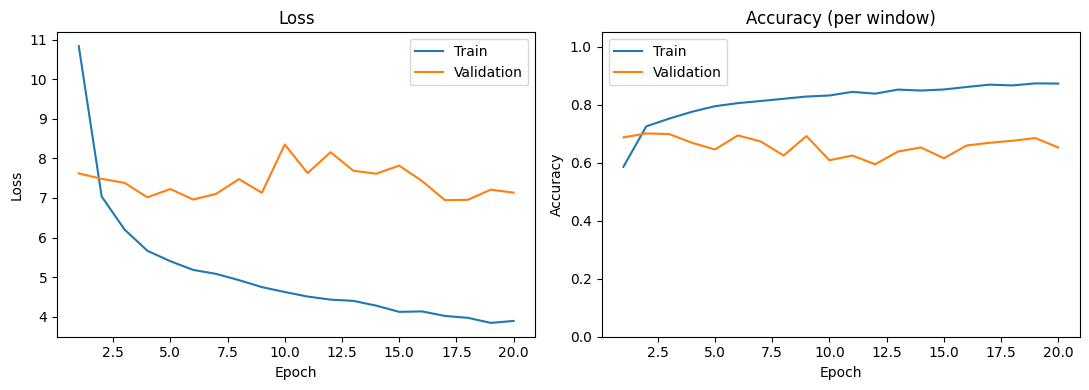

In [11]:
epochs = np.arange(1, NUM_EPOCHS + 1)
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))
ax_loss.plot(epochs, history['train_loss'], label='Train')
ax_loss.plot(epochs, history['val_loss'], label='Validation')
ax_loss.set_xlabel('Epoch'); ax_loss.set_ylabel('Loss'); ax_loss.set_title('Loss'); ax_loss.legend()
ax_acc.plot(epochs, history['train_acc'], label='Train')
ax_acc.plot(epochs, history['val_acc'], label='Validation')
ax_acc.set_xlabel('Epoch'); ax_acc.set_ylabel('Accuracy'); ax_acc.set_title('Accuracy (per window)'); ax_acc.legend()
ax_acc.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

## 10. Evaluation

The best model (lowest validation loss) is loaded again and every validation window is classified. The windows of each recording are then combined by **majority vote** to get one prediction per recording, which is usually more reliable than the prediction of a single window.

The results are saved in `OUTPUT_PATH/results.json`, so the folds of an experiment can be compared afterwards.

In [12]:
def evaluate(net, validation_loader, validation_npz, output_path, best_epoch, seed=None, verbose=True):
    """Classifies every validation window and every recording (majority vote) and saves results.json in output_path."""
    class_names = list(validation_npz['class_names'])
    net.eval()
    with torch.no_grad():
        window_predictions = torch.cat([net(frames.to(device)).sum(dim=0).argmax(dim=1).cpu()
                                        for frames, _ in validation_loader]).numpy()

    labels = validation_npz['labels']
    recordings = validation_npz['recordings']
    window_accuracy = float(np.mean(window_predictions == labels))
    if verbose:
        print('Window accuracy: {:.3f}\n'.format(window_accuracy))

    correct_recordings = 0
    for i, name in enumerate(validation_npz['recording_names']):
        mask = recordings == i
        if not mask.any():
            continue
        votes = np.bincount(window_predictions[mask], minlength=len(class_names))
        predicted, true = votes.argmax(), labels[mask][0]
        correct_recordings += predicted == true
        if verbose:
            print('{:<45} true: {:<12} predicted: {:<12} ({} of {} windows)'.format(
                name, class_names[true], class_names[predicted], votes[predicted], mask.sum()))

    num_recordings = len(np.unique(recordings))
    recording_accuracy = float(correct_recordings / num_recordings)
    if verbose:
        print('\nRecording accuracy: {} of {} ({:.3f})'.format(correct_recordings, num_recordings, recording_accuracy))

    with open(os.path.join(output_path, 'config.json')) as f:
        results = json.load(f)
    results.update(num_hidden=NUM_HIDDEN, beta=BETA, num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE,
                   batch_size=BATCH_SIZE, loss='mse_count_loss', correct_rate=CORRECT_RATE, incorrect_rate=INCORRECT_RATE, random_seed=seed, best_epoch=best_epoch, window_accuracy=window_accuracy,
                   recording_accuracy=recording_accuracy, num_validation_windows=int(len(labels)),
                   num_validation_recordings=int(num_recordings))
    with open(os.path.join(output_path, 'results.json'), 'w') as f:
        json.dump(results, f, indent=2)
    return results, window_predictions


results, window_predictions = evaluate(net, validation_loader, validation_npz, OUTPUT_PATH, best_epoch, seed)
labels = validation_npz['labels']

Window accuracy: 0.669

validation/balanced_no_tape/0003_1_Accel_3_No_No.aedat true: balanced_no_tape predicted: unbalanced_no_tape (21 of 27 windows)
validation/balanced_no_tape/0005_2_Accel_3_No_No.aedat true: balanced_no_tape predicted: balanced_no_tape (27 of 27 windows)
validation/balanced_no_tape/0021_1_Accel_6_No_No.aedat true: balanced_no_tape predicted: unbalanced_no_tape (19 of 27 windows)
validation/balanced_no_tape/0023_2_Accel_6_No_No.aedat true: balanced_no_tape predicted: balanced_no_tape (27 of 27 windows)
validation/balanced_tape/0145_1_Accel_3_No_Yes.aedat true: balanced_tape predicted: balanced_tape (17 of 27 windows)
validation/balanced_tape/0147_2_Accel_3_No_Yes.aedat true: balanced_tape predicted: balanced_tape (27 of 27 windows)
validation/balanced_tape/0157_1_Accel_6_No_Yes.aedat true: balanced_tape predicted: unbalanced_tape (21 of 27 windows)
validation/balanced_tape/0159_2_Accel_6_No_Yes.aedat true: balanced_tape predicted: balanced_tape (27 of 27 windows)
va

### Confusion matrix (per window)

Rows are the true classes and columns the predicted ones. Each row is normalised to 1, so the diagonal is the accuracy of each class. It shows which classes are confused with each other, for example 3 vs 6 magnets or 4 vs 5 magnets in the `3_load` experiments.

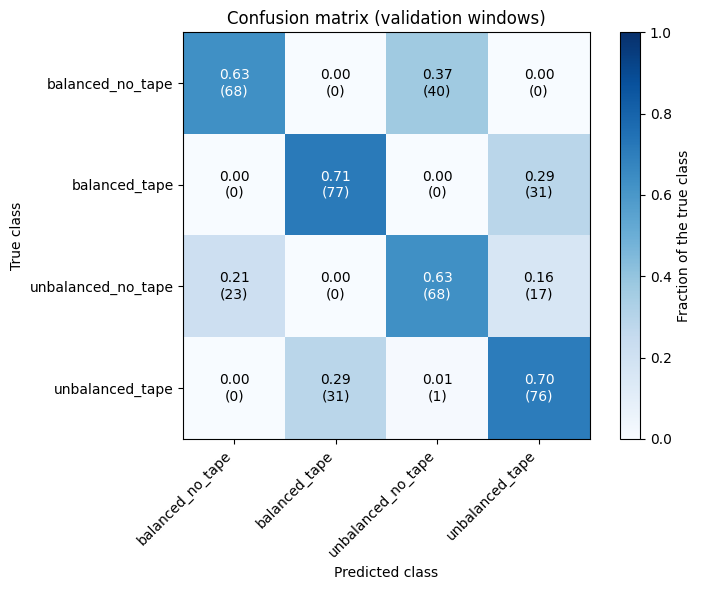

In [13]:
num_classes = len(CLASS_NAMES)
confusion = np.zeros((num_classes, num_classes), dtype=int)
np.add.at(confusion, (labels, window_predictions), 1)
normalised = confusion / np.maximum(confusion.sum(axis=1, keepdims=True), 1)

plt.figure(figsize=(1.2 * num_classes + 3, 1.0 * num_classes + 2))
plt.imshow(normalised, cmap='Blues', vmin=0, vmax=1)
for true in range(num_classes):
    for predicted in range(num_classes):
        plt.text(predicted, true, '{:.2f}\n({})'.format(normalised[true, predicted], confusion[true, predicted]),
                 ha='center', va='center', color='white' if normalised[true, predicted] > 0.5 else 'black')
plt.xticks(range(num_classes), CLASS_NAMES, rotation=45, ha='right')
plt.yticks(range(num_classes), CLASS_NAMES)
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.title('Confusion matrix (validation windows)')
plt.colorbar(label='Fraction of the true class')
plt.tight_layout()
plt.show()

## 11. Cross-validation over all folds (Fan NTAS dataset)

This cell repeats sections 2 and 5–10 for every fold (1 to `NUM_FOLDS`) of one experiment and sensor, with the parameters set above (window, time step, network and training). Each fold is built, prepared and saved in its own folder (`snn_dataset/experiments/<experiment>_<sensor>_fold<k>`), exactly as in a single run.

At the end it prints the accuracy of every fold, their mean ± standard deviation, and separately the accuracy of fold 4 (trained on 8 October, validated on 14 October), and saves them in `snn_dataset/experiments/<experiment>_<sensor>_cv.json`. Change `CV_RUNS` to run several experiments or sensors in a row.

If training fails in a fold (stuck at the chance level in both attempts, see section 8), the fold is reported as failed and left out of the mean ± standard deviation, and the other folds continue.

Each fold takes about 30 s to 10 min on a CPU, depending on the experiment.

In [ ]:
CV_RUNS = [(EXPERIMENT, SENSOR)]     # e.g. [('2a_unbalance_min', 'Mag'), ('3_load_min', 'Mag')]
FOLDS = list(range(1, NUM_FOLDS + 1))
CROSS_SESSION_FOLD = 4     # trains on 8 October, validates on 14 October


def cross_validate(experiment, sensor):
    fold_results = []
    for fold in FOLDS:
        experiment_path = os.path.join('snn_dataset', 'experiments', '{}_{}_fold{}'.format(experiment, sensor, fold))
        source_path = os.path.join(experiment_path, 'source')
        output_path = os.path.join(experiment_path, 'prepared')

        build_experiment(FAN_DATASET_PATH, source_path, experiment, sensor, fold, verbose=False)
        prepare_dataset(source_path, output_path, verbose=False)
        fold_train_npz, fold_validation_npz, fold_train_loader, fold_validation_loader = make_loaders(output_path)
        try:
            fold_net, _, fold_best_epoch, fold_seed = train_model(
                fold_train_loader, fold_validation_loader, len(fold_train_npz['class_names']), output_path, verbose=False)
        except TrainingFailedError as error:
            print('  {} {} fold {}: TRAINING FAILED\n    {}'.format(experiment, sensor, fold, str(error).replace('\n', '\n    ')))
            fold_results.append(dict(fold=fold, training_failed=True))
            continue
        fold_result, _ = evaluate(fold_net, fold_validation_loader, fold_validation_npz, output_path,
                                  fold_best_epoch, fold_seed, verbose=False)
        fold_result.update(fold=fold, training_failed=False)
        fold_results.append(fold_result)
        print('  {} {} fold {}: window accuracy {:.3f} | recording accuracy {:.3f} ({} recordings) | best epoch {} | seed {}'.format(
            experiment, sensor, fold, fold_result['window_accuracy'], fold_result['recording_accuracy'],
            fold_result['num_validation_recordings'], fold_best_epoch, fold_seed))

    trained = [r for r in fold_results if not r['training_failed']]
    window = np.array([r['window_accuracy'] for r in trained])
    recording = np.array([r['recording_accuracy'] for r in trained])
    summary = dict(experiment=experiment, sensor=sensor, folds=FOLDS,
                   failed_folds=[r['fold'] for r in fold_results if r['training_failed']],
                   window_accuracy_mean=float(window.mean()) if trained else None,
                   window_accuracy_std=float(window.std()) if trained else None,
                   recording_accuracy_mean=float(recording.mean()) if trained else None,
                   recording_accuracy_std=float(recording.std()) if trained else None,
                   fold_results=fold_results)
    with open(os.path.join('snn_dataset', 'experiments', '{}_{}_cv.json'.format(experiment, sensor)), 'w') as f:
        json.dump(summary, f, indent=2)
    return summary


if os.path.isdir(FAN_DATASET_PATH):
    cv_summaries = []
    for experiment, sensor in CV_RUNS:
        print('{} ({}): {}'.format(experiment, sensor, EXPERIMENTS[experiment]['description']))
        cv_summaries.append(cross_validate(experiment, sensor))

    print('\n{:<28} {:<6} {:>22} {:>25} {:>28} {:>14}'.format('Experiment', 'Sensor', 'Window accuracy', 'Recording accuracy',
                                                             'Fold {} window / recording'.format(CROSS_SESSION_FOLD), 'Failed folds'))
    for s in cv_summaries:
        cross_session = s['fold_results'][FOLDS.index(CROSS_SESSION_FOLD)] if CROSS_SESSION_FOLD in FOLDS else None
        if cross_session is None:
            cross_session_text = '-'
        elif cross_session['training_failed']:
            cross_session_text = 'failed'
        else:
            cross_session_text = '{:.3f} / {:.3f}'.format(cross_session['window_accuracy'], cross_session['recording_accuracy'])
        if s['window_accuracy_mean'] is None:
            accuracy_text = '{:>22} {:>25}'.format('all folds failed', '-')
        else:
            accuracy_text = '{:>14.3f} ± {:.3f} {:>17.3f} ± {:.3f}'.format(
                s['window_accuracy_mean'], s['window_accuracy_std'], s['recording_accuracy_mean'], s['recording_accuracy_std'])
        print('{:<28} {:<6} {} {:>20} {:>14}'.format(s['experiment'], s['sensor'], accuracy_text, cross_session_text,
                                                     ', '.join(map(str, s['failed_folds'])) or '-'))
else:
    print('Cross-validation needs the Fan NTAS dataset in', FAN_DATASET_PATH)